In [1]:
import geopandas as gpd
from utils import *
import matplotlib.pyplot as plt
from os import mkdir, path, getcwd

<StringArray>
[        'forest',          'grass',           'park',          'scrub',
 'nature_reserve',          'heath',       'farmyard',       'farmland']
Length: 8, dtype: str
          osm_id  code  fclass name  \
27900  556600072  7201  forest  NaN   
27899  556600070  7201  forest  NaN   
28001  556874818  7218   grass  NaN   
27693  556367025  7218   grass  NaN   
28018  556878639  7201  forest  NaN   

                                                geometry  
27900  POLYGON ((0.20062 51.54228, 0.20075 51.54225, ...  
27899  POLYGON ((0.20054 51.5424, 0.2006 51.54245, 0....  
28001  POLYGON ((0.20275 51.54278, 0.20276 51.54263, ...  
27693  POLYGON ((0.20256 51.5427, 0.20259 51.54259, 0...  
28018  POLYGON ((0.20211 51.54253, 0.20216 51.54253, ...  
EPSG:4326


<Axes: >

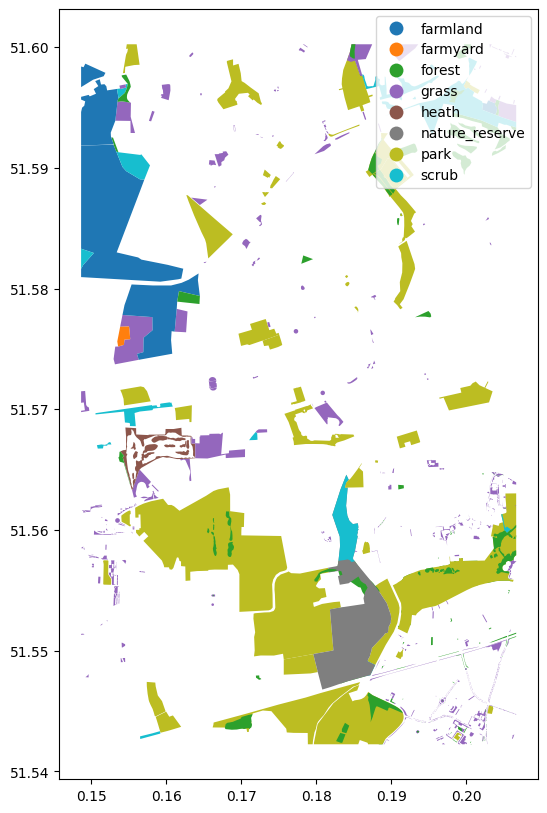

In [2]:
roads = gpd.read_file("shp/gis_osm_landuse_a_free_1.shp")

roads = roads[roads["fclass"].isin([
    "scrub",
    "farmland",
    "grass",
    "forest",
    "heath",
    "park",
    "meadow",
    "nature_reserve",
    "farmyard",
])]

# Clip to a 2-mile radius around the specified coordinates
bbox_lon, bbox_lat = 0.1776647, 51.5712405
# Approximately 2 miles = 3.22 km, in degrees ≈ 0.029 degrees
delta = 0.029
bbox = (bbox_lon - delta, bbox_lat - delta, bbox_lon + delta, bbox_lat + delta)
roads = clip_to_bbox(roads, bbox, width_map=None)

print(roads["fclass"].unique())
print(roads.head())
print(roads.crs)

roads.plot("fclass", figsize=(10,10), legend=True)

In [4]:
check = checkered_patter()
check.show()

kf.service.services: KApplicationTrader: mimeType "x-scheme-handler/file" not found
kf.service.services: KApplicationTrader: mimeType "x-scheme-handler/file" not found
org.kde.kdegraphics.gwenview.lib: Unresolved mime type  "image/x-mng"
org.kde.kdegraphics.gwenview.lib: Unresolved raw mime type  "image/x-nikon-nrw"
org.kde.kdegraphics.gwenview.lib: Unresolved raw mime type  "image/x-samsung-srw"
org.kde.kdegraphics.gwenview.lib: Gwenview cannot apply color profile on QImage::Format_Mono images


In [3]:
test_zoom = 14

# Romford tile coordinates
romford_tile = tile_from_lonlat(0.1786, 51.5775, test_zoom)

test_tile = render_roads_to_tile(
    roads,
    x=romford_tile[0],
    y=romford_tile[1],
    z=test_zoom,
    tile_size=120,
    )

test_tile.show()

kf.service.services: KApplicationTrader: mimeType "x-scheme-handler/file" not found
kf.service.services: KApplicationTrader: mimeType "x-scheme-handler/file" not found
org.kde.kdegraphics.gwenview.lib: Unresolved mime type  "image/x-mng"
org.kde.kdegraphics.gwenview.lib: Unresolved raw mime type  "image/x-nikon-nrw"
org.kde.kdegraphics.gwenview.lib: Unresolved raw mime type  "image/x-samsung-srw"


In [5]:
from PIL import ImageChops
mult = ImageChops.multiply(check, test_tile)
mult.show()

kf.service.services: KApplicationTrader: mimeType "x-scheme-handler/file" not found
kf.service.services: KApplicationTrader: mimeType "x-scheme-handler/file" not found
org.kde.kdegraphics.gwenview.lib: Unresolved mime type  "image/x-mng"
org.kde.kdegraphics.gwenview.lib: Unresolved raw mime type  "image/x-nikon-nrw"
org.kde.kdegraphics.gwenview.lib: Unresolved raw mime type  "image/x-samsung-srw"
org.kde.kdegraphics.gwenview.lib: Gwenview cannot apply color profile on QImage::Format_Mono images
